# PCA on CLIP Emotions

This notebook will give the basic setup for performing PCA on different emotion word embeddings for a CLIP model. When we do this, we find that the low-dimensional structure we obtain closely matches the valence-arousal model.

## Setup

Firstly, let's set up our script by downloading libraries, managing imports, and downloading the SDXL model.

In [1]:
from diffusers import DiffusionPipeline
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

In [2]:
pipe = DiffusionPipeline.from_pretrained("stabilityai/stable-diffusion-xl-base-1.0", torch_dtype=torch.float16, use_safetensors=True, variant="fp16")
pipe.to("cuda")
pipe.set_progress_bar_config(disable=True)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

## Principal Component Analysis

Next, let's get text embeddings for a number of different emotion words and perform PCA on these embeddings. We will use the prompt template `"a portrait photo with a {emotion} face"` for our prompts.

In [3]:
emotion_colors = [
    ("happy", "#FF0000"),
    ("sad", "#00A0FF"),
    ("sleeping", "#D000FF"),
    ("surprised", "#FFFF00"),
    ("relaxed", "#F000FF"),
    ("bored", "#B000FF"),
    ("disgusted", "#00FF40"),
    ("angry", "#00FFA0"),
    ("excited", "#FF4000"),
    ("neutral", "#FF30FF"),
    ("interested", "#FF2000"),
    ("joyful", "#FF6000"),
    ("amused", "#FF8000"),
    ("awe", "#FFA000"),
    ("shocked", "#A0FF00"),
    ("scared", "#80FF00"),
    ("terrified", "#40FF00"),
    ("contempt", "#00FF00"),
    ("confused", "#20FF20"),
    ("annoyed", "#00FFF0"),
    ("upset", "#0060FF"),
    ("depressed", "#0010FF"),
    ("awkward", "#7000FF"),
]

# Now, let's create the new list with the prompt template
emotion_prompts = [f"a portrait photo with a {emotion} face" for emotion, _ in emotion_colors]

# Print out our prompts
print("-"*21)
print("-- EMOTION PROMPTS --")
print("-"*21)
for p in emotion_prompts:
  print(f' • "{p}"')

---------------------
-- EMOTION PROMPTS --
---------------------
 • "a portrait photo with a happy face"
 • "a portrait photo with a sad face"
 • "a portrait photo with a sleeping face"
 • "a portrait photo with a surprised face"
 • "a portrait photo with a relaxed face"
 • "a portrait photo with a bored face"
 • "a portrait photo with a disgusted face"
 • "a portrait photo with a angry face"
 • "a portrait photo with a excited face"
 • "a portrait photo with a neutral face"
 • "a portrait photo with a interested face"
 • "a portrait photo with a joyful face"
 • "a portrait photo with a amused face"
 • "a portrait photo with a awe face"
 • "a portrait photo with a shocked face"
 • "a portrait photo with a scared face"
 • "a portrait photo with a terrified face"
 • "a portrait photo with a contempt face"
 • "a portrait photo with a confused face"
 • "a portrait photo with a annoyed face"
 • "a portrait photo with a upset face"
 • "a portrait photo with a depressed face"
 • "a portrait 

Get our text embeddings from the CLIP encoder.

In [4]:
# Get text embeddings from our CLIP encodeds in SDXL
device = "cuda" if torch.cuda.is_available() else "cpu"
text_features = np.zeros((len(emotion_prompts), 77, 2048))
pooled_text_features = np.zeros((len(emotion_prompts), 1280))
with torch.no_grad():
    # Iterate over all emotion prompts
    for e in range(len(emotion_prompts)):
        text_feature, _, pooled_text_feature, _ = pipe.encode_prompt(emotion_prompts[e])
        text_features[e] = text_feature.detach().cpu().numpy()
        pooled_text_features[e] = pooled_text_feature.detach().cpu().numpy()

Perform PCA on the text embeddings.

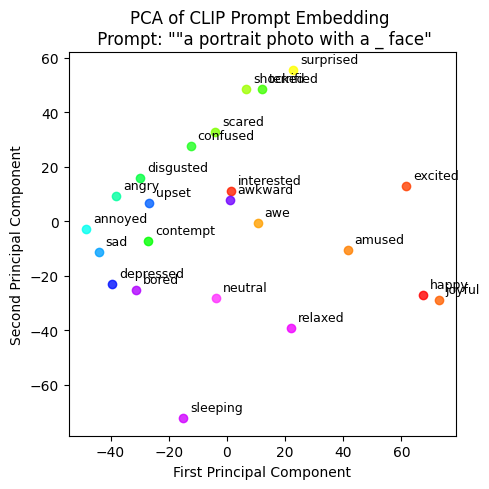

In [6]:
# Get token IDs
text = pipe.tokenizer(emotion_prompts)

# Perform PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(text_features.reshape(len(text.input_ids), 77 * 2048))
X_comp = pca.components_.reshape(2,77,2048)
X_mean_pooled = np.mean(pooled_text_features, axis=0)
X_mean = np.mean(text_features, axis=0)

# Plot the results
plt.figure(figsize=(5, 5))
#plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.8)
plt.title('PCA of CLIP Prompt Embedding \n Prompt: \""a portrait photo with a _ face\"')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')

# Add labels for each point
for i, (x, y) in enumerate(X_pca):
    plt.scatter(x, -y, alpha=0.8, c=emotion_colors[i][1])
    plt.annotate(emotion_colors[i][0], (x, -y), xytext=(5, 5), textcoords='offset points', fontsize=9)

plt.tight_layout()